# EV Charging Station Recommendation Milestone-3
This notebook explains each implementation step.

## Step 1: Testing the Fuzzy Controller

The fuzzy controller is tested using different combinations of
Distance, Slot Availability, and Charging Cost.

At least 10 different input combinations are used to evaluate the
behaviour of the EV Charging Station Recommendation system under
different charging station conditions.

The test cases include combinations representing favourable,
moderate, and unfavourable charging station conditions.

In [ ]:
# Step 1: Define 10 different test cases

test_cases = [
    {"distance": 1,  "availability": 95, "cost": 3},
    {"distance": 2,  "availability": 90, "cost": 5},
    {"distance": 4,  "availability": 65, "cost": 9},
    {"distance": 5,  "availability": 80, "cost": 7},
    {"distance": 7,  "availability": 60, "cost": 10},
    {"distance": 8,  "availability": 50, "cost": 12},
    {"distance": 10, "availability": 50, "cost": 10},
    {"distance": 12, "availability": 20, "cost": 18},
    {"distance": 14, "availability": 10, "cost": 19},
    {"distance": 15, "availability": 5,  "cost": 20}
]

print("Total Test Cases:", len(test_cases))

## Step 2: Run the Fuzzy Controller on the Test Cases

Each test case is passed through the fuzzy inference system using the
same membership functions and fuzzy rules defined in the EV Charging
Station Recommendation controller.

The resulting recommendation score is recorded for each combination
of distance, slot availability, and charging cost.

In [96]:
# Step 2: Run all 10 test cases

test_results = []

for i, case in enumerate(test_cases, 1):

    test_simulation = ctrl.ControlSystemSimulation(charging_ctrl)

    test_simulation.input['distance'] = case['distance']
    test_simulation.input['availability'] = case['availability']
    test_simulation.input['cost'] = case['cost']

    test_simulation.compute()

    score = test_simulation.output['recommendation']

    test_results.append({
        "Test Case": i,
        "Distance (km)": case['distance'],
        "Availability (%)": case['availability'],
        "Cost ($/kWh)": case['cost'],
        "Recommendation Score": round(score, 2)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df

,Test Case,Distance (km),Availability (%),Cost ($/kWh),Recommendation Score
0,1,1,95,3,85.30
1,2,2,90,5,83.46
2,3,4,65,9,61.85
3,4,5,80,7,81.22
4,5,7,60,10,50.00
5,6,8,50,12,50.00
6,7,10,50,10,50.00
7,8,12,20,18,15.56
8,9,14,10,19,14.00
9,10,15,5,20,13.52


## Step 3: Analysis of Test Results

The recommendation scores obtained from the 10 test cases are analyzed
to understand how the fuzzy controller responds to different charging
station conditions.

The analysis considers the effect of:

- Distance from the charging station
- Slot availability
- Charging cost

The results are used to identify favourable and unfavourable charging
station conditions and to evaluate the overall behaviour of the fuzzy
controller.

In [97]:
# Step 3: Display the test results clearly

test_results_df

,Test Case,Distance (km),Availability (%),Cost ($/kWh),Recommendation Score
0,1,1,95,3,85.30
1,2,2,90,5,83.46
2,3,4,65,9,61.85
3,4,5,80,7,81.22
4,5,7,60,10,50.00
5,6,8,50,12,50.00
6,7,10,50,10,50.00
7,8,12,20,18,15.56
8,9,14,10,19,14.00
9,10,15,5,20,13.52


In [98]:
# Find the highest and lowest recommendation scores

highest = test_results_df.loc[
    test_results_df["Recommendation Score"].idxmax()
]

lowest = test_results_df.loc[
    test_results_df["Recommendation Score"].idxmin()
]

print("Highest Recommendation:")
print(highest)

print("\nLowest Recommendation:")
print(lowest)

Highest Recommendation:
Test Case                1.0
Distance (km)            1.0
Availability (%)        95.0
Cost ($/kWh)             3.0
Recommendation Score    85.3
Name: 0, dtype: float64

Lowest Recommendation:
Test Case               10.00
Distance (km)           15.00
Availability (%)         5.00
Cost ($/kWh)            20.00
Recommendation Score    13.52
Name: 9, dtype: float64


### Visualize Test Results

Let's visualize the relationship between the input variables (Distance, Availability, Cost) and the Recommendation Score.

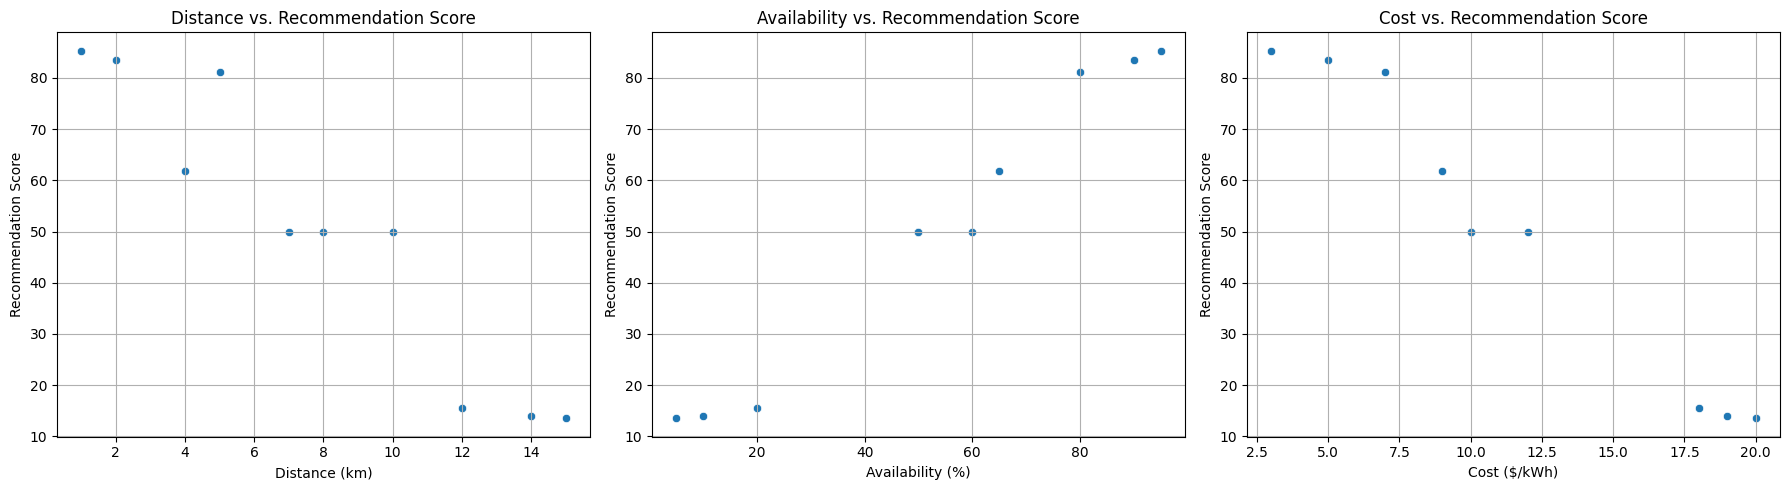

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x='Distance (km)', y='Recommendation Score', data=test_results_df)
plt.title('Distance vs. Recommendation Score')
plt.grid(True)

plt.subplot(1, 3, 2)
sns.scatterplot(x='Availability (%)', y='Recommendation Score', data=test_results_df)
plt.title('Availability vs. Recommendation Score')
plt.grid(True)

plt.subplot(1, 3, 3)
sns.scatterplot(x='Cost ($/kWh)', y='Recommendation Score', data=test_results_df)
plt.title('Cost vs. Recommendation Score')
plt.grid(True)

plt.tight_layout()
plt.show()

## Step 4: Controller Behaviour Analysis

The EV Charging Station Recommendation fuzzy controller combines
Distance, Slot Availability, and Charging Cost to produce a single
Recommendation Score.

The controller generally gives a more favourable recommendation when
the charging station is closer, has higher slot availability, and has
a lower charging cost.

When the distance is higher, slot availability is lower, or charging
cost is higher, the recommendation becomes less favourable.

The fuzzy approach allows the controller to handle combinations of
these inputs rather than making a decision based on only one factor.

### Strengths of the Controller

- It considers multiple charging-station factors simultaneously.
- It can handle gradual changes in distance, availability, and cost.
- Fuzzy rules provide an interpretable way to make recommendations.
- The output is converted into a single Recommendation Score, making
  the result easier to understand.
- The controller can be tested with different charging-station
  conditions.

### Weaknesses of the Controller

- The recommendation depends on the membership functions and fuzzy
  rules defined for the system.
- The current controller uses a limited number of fuzzy rules.
- Real-world charging-station conditions may change over time.
- The system does not account for factors that are outside the
  defined inputs.

### Scope for Improvement

The system can be improved by adding more relevant charging-station
factors and refining the membership functions and fuzzy rules.

The controller could also be tested with a larger number of real-world
charging-station conditions to evaluate its performance more
thoroughly.

## Step 5: Create a User Interface

A simple user interface is created for the EV Charging Station
Recommendation fuzzy controller.

The user can enter the Distance, Slot Availability, and Charging Cost
of a charging station.

The fuzzy controller then processes these inputs and displays the
resulting Recommendation Score.

In [ ]:
# Step 5: Create the User Interface

import ipywidgets as widgets
from IPython.display import display, clear_output

distance_input = widgets.FloatSlider(
    value=4,
    min=0,
    max=15,
    step=0.1,
    description='Distance:',
    style={'description_width': 'initial'}
)

availability_input = widgets.IntSlider(
    value=65,
    min=0,
    max=100,
    step=1,
    description='Availability:',
    style={'description_width': 'initial'}
)

cost_input = widgets.FloatSlider(
    value=9,
    min=0,
    max=20,
    step=0.1,
    description='Cost:',
    style={'description_width': 'initial'}
)

calculate_button = widgets.Button(
    description='Get Recommendation',
    button_style='primary'
)

output = widgets.Output()

def calculate_recommendation(b):
    with output:
        clear_output()

        simulation = ctrl.ControlSystemSimulation(charging_ctrl)

        simulation.input['distance'] = distance_input.value
        simulation.input['availability'] = availability_input.value
        simulation.input['cost'] = cost_input.value

        simulation.compute()

        score = simulation.output['recommendation']

        print("EV Charging Station Recommendation")
        print("-----------------------------------")
        print(f"Distance: {distance_input.value:.1f} km")
        print(f"Availability: {availability_input.value}%")
        print(f"Charging Cost: ${cost_input.value:.1f}/kWh")
        print(f"Recommendation Score: {score:.2f}")

calculate_button.on_click(calculate_recommendation)

display(
    distance_input,
    availability_input,
    cost_input,
    calculate_button,
    output
)

FloatSlider(value=4.0, description='Distance:', max=15.0, style=SliderStyle(description_width='initial'))

IntSlider(value=65, description='Availability:', style=SliderStyle(description_width='initial'))

FloatSlider(value=9.0, description='Cost:', max=20.0, style=SliderStyle(description_width='initial'))

Button(button_style='primary', description='Get Recommendation', style=ButtonStyle())

Output()

# Task
The user wants to evaluate and visualize the fuzzy logic system for EV charging station recommendations. This involves generating comprehensive test data, evaluating the fuzzy system across all test data using the 'centroid' defuzzification method, visualizing the system's response using both 3D surface plots and 2D line plots, analyzing the performance with descriptive statistics, and finally summarizing the findings.

## Generate Comprehensive Test Data

### Subtask:
Generate a comprehensive set of input combinations for 'distance', 'availability', and 'cost' to cover the entire input space of the fuzzy system. Store these combinations in a Pandas DataFrame.


**Reasoning**:
Generate comprehensive test data for the fuzzy system by creating arrays for each input variable, combining them with `np.meshgrid`, and storing them in a Pandas DataFrame as instructed.



In [ ]:
n_points = 20 # Using 20 points for each variable to keep the dataset size manageable for visualization purposes.

# 1. Create linearly spaced arrays for each input variable
distances_test = np.linspace(0, 15, n_points)
availability_test = np.linspace(0, 100, n_points)
cost_test = np.linspace(0, 20, n_points)

# 2. Use np.meshgrid to generate all possible combinations
D, A, C = np.meshgrid(distances_test, availability_test, cost_test)

# 3. Convert the generated meshgrid data into a Pandas DataFrame
test_data_comprehensive = pd.DataFrame({
    'distance': D.ravel(),
    'availability': A.ravel(),
    'cost': C.ravel()
})

# 4. Display the head of the resulting DataFrame and its shape
print("Head of comprehensive test data:")
print(test_data_comprehensive.head())
print("\nShape of comprehensive test data:")
print(test_data_comprehensive.shape)

Head of comprehensive test data:
   distance  availability      cost
0       0.0           0.0  0.000000
1       0.0           0.0  1.052632
2       0.0           0.0  2.105263
3       0.0           0.0  3.157895
4       0.0           0.0  4.210526

Shape of comprehensive test data:
(8000, 3)


## Evaluate Fuzzy System with Comprehensive Test Data

### Subtask:
Evaluate the fuzzy system for each combination of 'distance', 'availability', and 'cost' in the `test_data_comprehensive` DataFrame. Store the resulting recommendation scores in a new column within the DataFrame.


## Visualize Fuzzy System Response with 3D Surface Plots

### Subtask:
Create a 3D surface plot to visualize the fuzzy system's response. Since a 3D plot can only show three dimensions at a time, we will hold one variable constant (e.g., cost) and plot the recommendation score as a function of distance and availability.


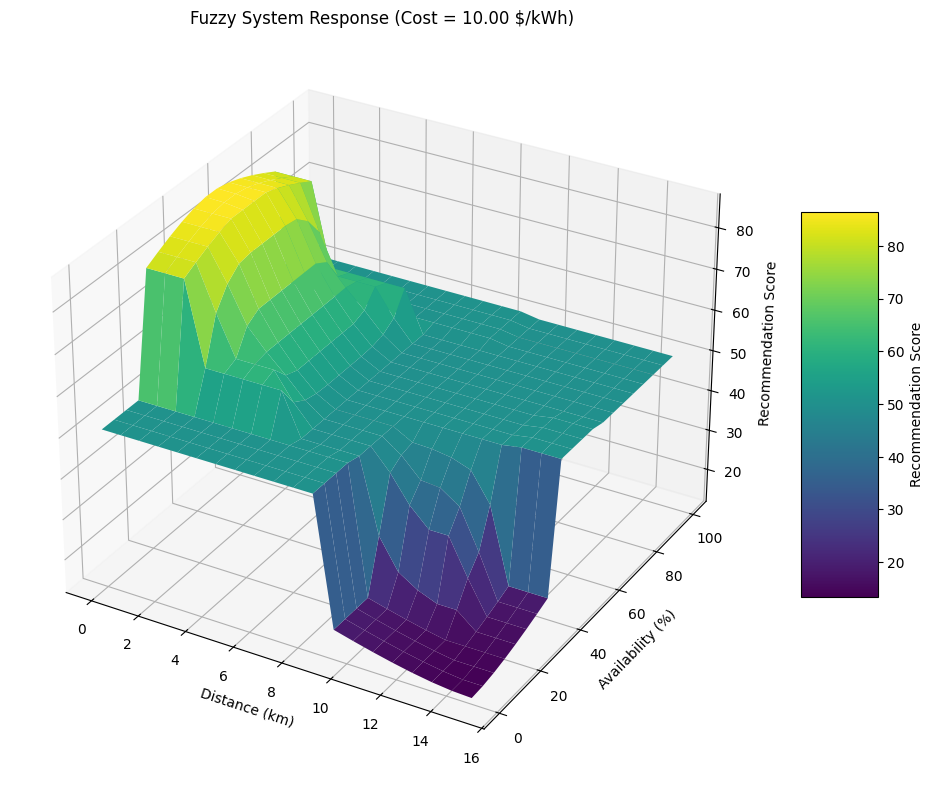

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# Let's pick a median cost for visualization from the original test data range
median_cost = np.median(cost_test) # Using cost_test for median as it represents the universe

# Create a new meshgrid specifically for the 3D plot at a constant cost
X_plot, Y_plot = np.meshgrid(distances_test, availability_test)

# Initialize an array to store the recommendation scores
Z_plot = np.zeros(X_plot.shape)

# Calculate recommendation scores for each point in the meshgrid at the median cost
# This loop computes the recommendation score for a 2D grid (Distance, Availability) at a fixed Cost
for i in range(X_plot.shape[0]):
    for j in range(X_plot.shape[1]):
        dist_val = X_plot[i, j]
        avail_val = Y_plot[i, j]
        score = get_recommendation_score(dist_val, avail_val, median_cost)
        Z_plot[i, j] = score

# Handle potential NaN values (e.g., where fuzzy system had no recommendation)
# For surface plots, NaNs can cause issues. We can interpolate or set to a default value.
# For now, let's fill NaNs with the mean of non-NaN values for better visualization clarity.
# If there are no non-NaN values, default to 0 or another sensible value.
if np.isnan(Z_plot).all():
    print("Warning: All recommendation scores are NaN for the selected cost slice. Cannot plot surface.")
else:
    mean_score = np.nanmean(Z_plot)
    Z_plot[np.isnan(Z_plot)] = mean_score

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(X_plot, Y_plot, Z_plot, cmap='viridis')

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Availability (%)')
ax.set_zlabel('Recommendation Score')
ax.set_title(f'Fuzzy System Response (Cost = {median_cost:.2f} $/kWh)')

fig.colorbar(surface, shrink=0.5, aspect=5, label='Recommendation Score')
plt.show()

## Visualize Fuzzy System Response with a '4D' Scatter Plot

Since a true 4D plot is not possible, we can use color to represent the fourth dimension (Cost) in a 3D scatter plot. This will allow us to observe how the recommendation score changes with Distance, Availability, and Cost simultaneously.

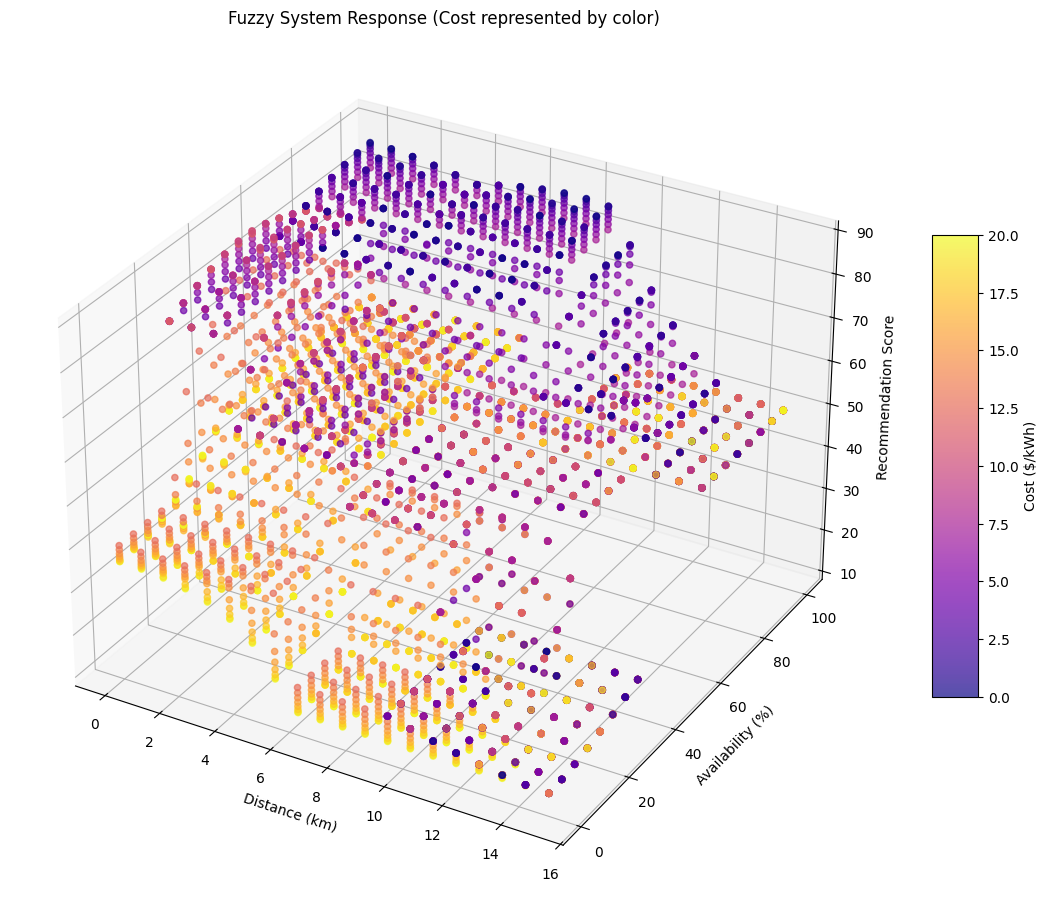

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

# Prepare data for plotting
# We'll use the comprehensive test data, but first drop rows with NaN recommendation scores
plot_data = test_data_comprehensive.dropna(subset=['recommendation_score'])

X = plot_data['distance'].values
Y = plot_data['availability'].values
Z = plot_data['recommendation_score'].values
C = plot_data['cost'].values  # Fourth dimension represented by color

# Create the 3D scatter plot
scatter = ax.scatter(X, Y, Z, c=C, cmap='plasma', s=20, alpha=0.7)

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Availability (%)')
ax.set_zlabel('Recommendation Score')
ax.set_title('Fuzzy System Response (Cost represented by color)')

# Add a color bar to indicate the cost values
cbar = fig.colorbar(scatter, shrink=0.5, aspect=10, label='Cost ($/kWh)')

plt.show()

## Step 6: Display the Recommendation Score

The user interface displays the values entered by the user and the
Recommendation Score calculated by the fuzzy controller.

The Recommendation Score is obtained directly from the fuzzy inference
system using the defined membership functions and fuzzy rules.

In [ ]:
def calculate_recommendation(b):
    with output:
        clear_output()

        simulation = ctrl.ControlSystemSimulation(charging_ctrl)

        simulation.input['distance'] = distance_input.value
        simulation.input['availability'] = availability_input.value
        simulation.input['cost'] = cost_input.value

        simulation.compute()

        score = simulation.output['recommendation']

        print("EV Charging Station Recommendation")
        print("-----------------------------------")
        print(f"Distance: {distance_input.value:.1f} km")
        print(f"Availability: {availability_input.value}%")
        print(f"Charging Cost: ${cost_input.value:.1f}/kWh")
        print(f"Recommendation Score: {score:.2f}")

## Step 7: Test the User Interface

The user interface is tested using different combinations of Distance,
Slot Availability, and Charging Cost.

The inputs are changed and the Recommendation Score is observed to
verify that the fuzzy controller responds to different charging
station conditions.

## Step 8: Final User Interface Demonstration

The completed user interface allows the user to provide the three
inputs required by the EV Charging Station Recommendation fuzzy
controller:

- Distance from the charging station
- Slot Availability
- Charging Cost

After the user provides the inputs, the fuzzy controller processes
them using the defined membership functions and fuzzy rules and
displays the resulting Recommendation Score.

The interface can be tested with different combinations of inputs to
observe how the Recommendation Score changes.